In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset path
data_path = (
    Path(r"D:\Yuva Intern Tasks\Task 3")
    / "Dataset"
    / "online+retail"
    / "Online Retail.xlsx"
)

print("Dataset exists:", data_path.exists())

# Load dataset
df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset exists: True
Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
from pathlib import Path

base_path = Path(r"D:\Yuva Intern Tasks")

for file in base_path.rglob("Online Retail.xlsx"):
    print("Dataset found:", file)

Dataset found: D:\Yuva Intern Tasks\Task 3\Dataset\online+retail\Online Retail.xlsx
Dataset found: D:\Yuva Intern Tasks\Task 2\Dataset\online+retail\Online Retail.xlsx
Dataset found: D:\Yuva Intern Tasks\task 1\Dataset\online+retail\Online Retail.xlsx


In [4]:
data_path = Path(
    r"D:\Yuva Intern Tasks\Task 2\Dataset\online+retail\Online Retail.xlsx"
)

df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
# Step 3: Prepare data for visualization

# Check dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Create Revenue column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Create Year-Month column
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)

# Display prepared data
display(df.head())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12



Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0
YearMonth           0
dtype: int64


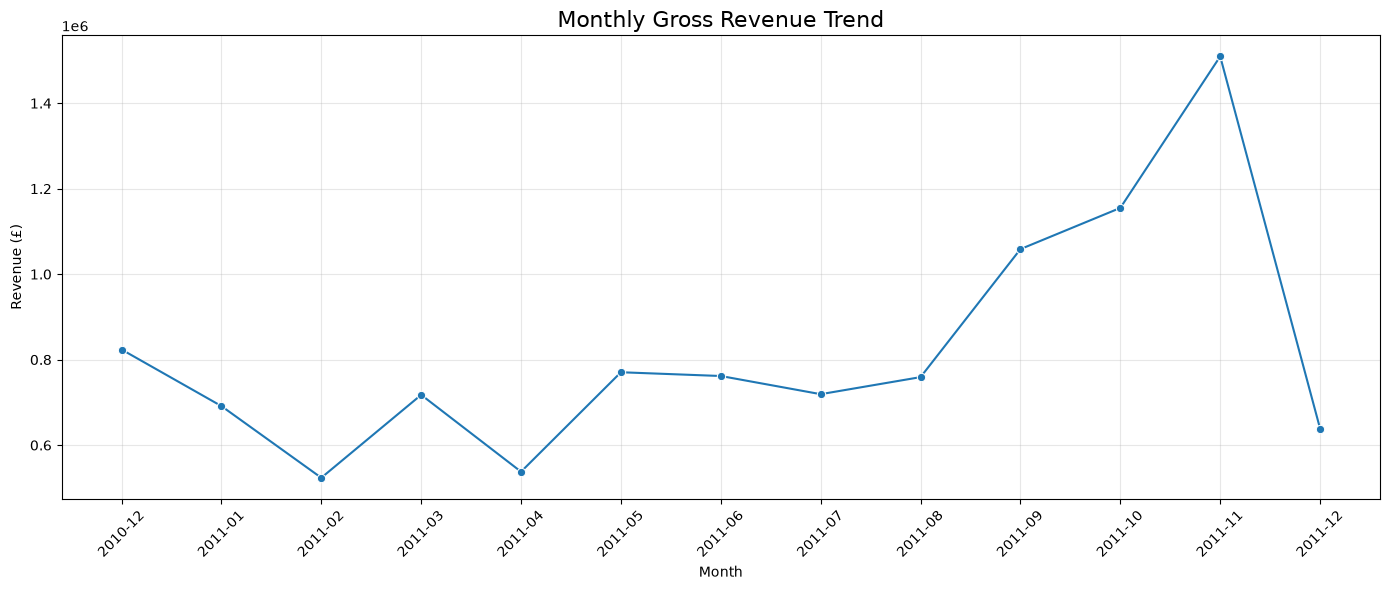

In [8]:

# Step 4: Monthly Revenue Line Chart

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Charts folder create karo agar nahi hai
Path("Charts").mkdir(parents=True, exist_ok=True)

# Positive sales records only
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Monthly revenue calculate karo
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

monthly_sales = (
    sales_df.groupby(
        sales_df["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

# Line chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Gross Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "Charts/Monthly_Revenue_Line_Chart.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


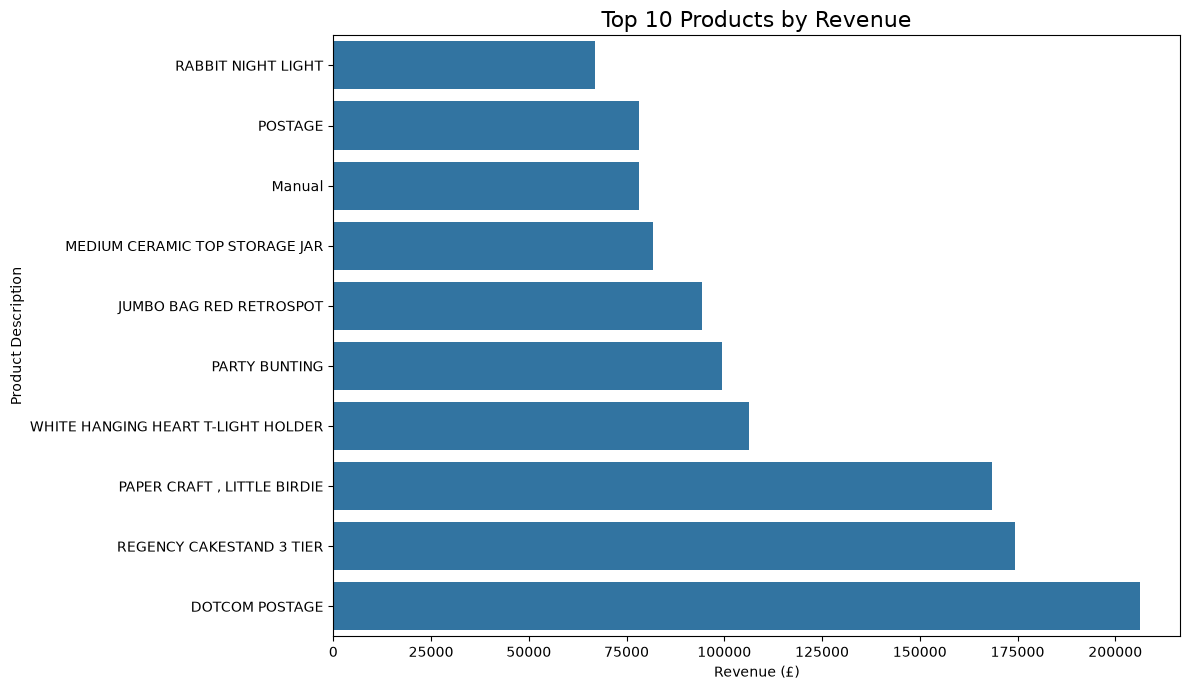

In [9]:

# Step 5: Top 10 Products by Revenue

import matplotlib.pyplot as plt
import seaborn as sns

# Positive sales records
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["Description"].notna())
].copy()

# Calculate revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Top 10 products by revenue
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Create bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Product Description")
plt.tight_layout()

# Save chart
plt.savefig(
    "Charts/Top_10_Products_Bar_Chart.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


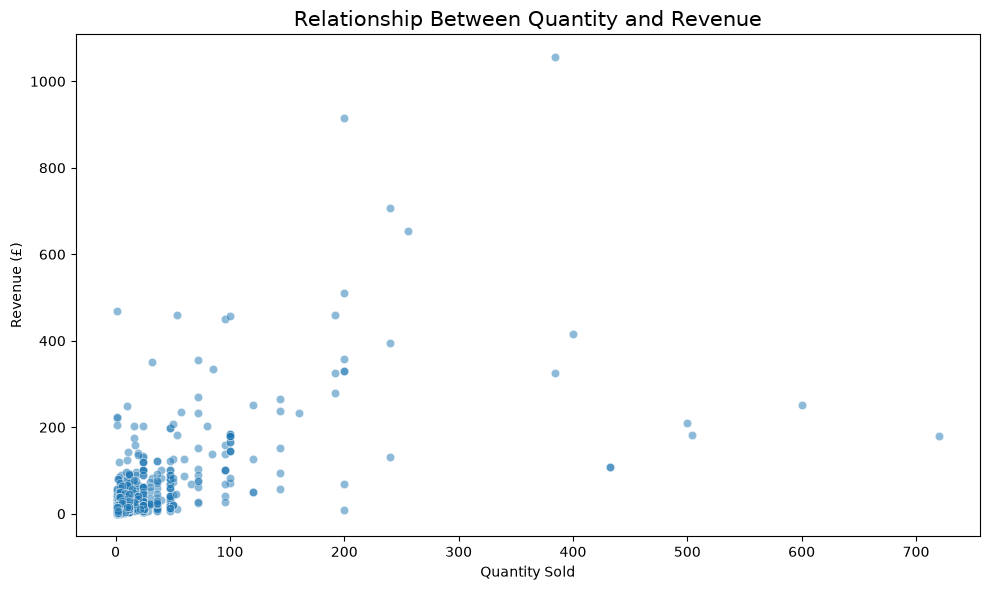

In [10]:

# Step 6: Scatter Plot - Quantity vs Revenue

import matplotlib.pyplot as plt
import seaborn as sns

# Positive sales records only
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Sample data for a clearer chart
plot_df = sales_df.sample(
    n=min(3000, len(sales_df)),
    random_state=42
)

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="Quantity",
    y="Revenue",
    alpha=0.5
)

plt.title("Relationship Between Quantity and Revenue", fontsize=15)
plt.xlabel("Quantity Sold")
plt.ylabel("Revenue (£)")
plt.tight_layout()

# Save chart
plt.savefig(
    "Charts/Quantity_vs_Revenue_Scatter_Plot.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


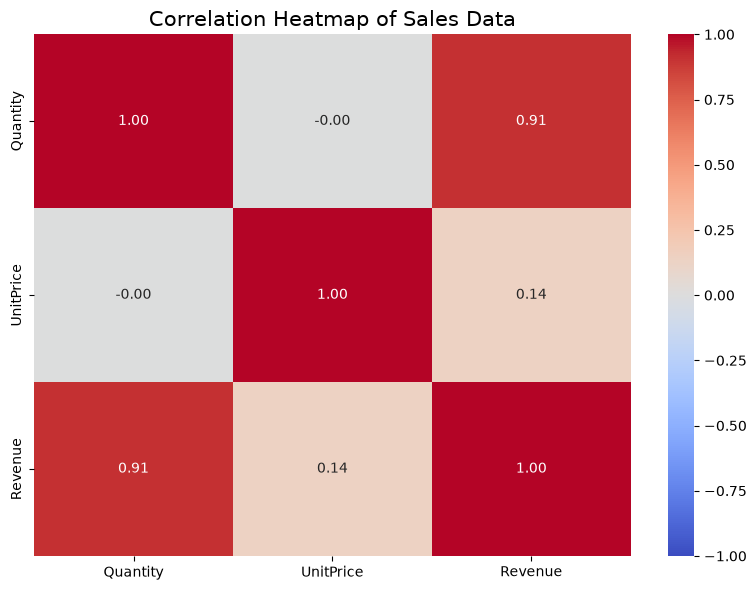

In [11]:

# Step 7: Correlation Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Positive sales records
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Select numerical columns
numeric_df = sales_df[
    ["Quantity", "UnitPrice", "Revenue"]
]

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Sales Data", fontsize=15)
plt.tight_layout()

# Save chart
plt.savefig(
    "Charts/Sales_Correlation_Heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [12]:

# Step 8: Verify all charts

from pathlib import Path

charts_folder = Path("Charts")

required_charts = [
    "Monthly_Revenue_Line_Chart.png",
    "Top_10_Products_Bar_Chart.png",
    "Quantity_vs_Revenue_Scatter_Plot.png",
    "Sales_Correlation_Heatmap.png"
]

for chart in required_charts:
    chart_path = charts_folder / chart

    if chart_path.exists():
        print(f"✅ Found: {chart}")
    else:
        print(f"❌ Missing: {chart}")


✅ Found: Monthly_Revenue_Line_Chart.png
✅ Found: Top_10_Products_Bar_Chart.png
✅ Found: Quantity_vs_Revenue_Scatter_Plot.png
✅ Found: Sales_Correlation_Heatmap.png


In [13]:

# Step 9: Generate Data Insights

# 1. Monthly revenue insight
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

lowest_month = monthly_sales.idxmin()
lowest_month_revenue = monthly_sales.min()

# 2. Top product insight
top_product = top_products.idxmax()
top_product_revenue = top_products.max()

# 3. Quantity and revenue correlation
quantity_revenue_corr = correlation.loc[
    "Quantity", "Revenue"
]

# Display insights
print("WEEK 3 - DATA VISUALIZATION INSIGHTS")
print("-" * 45)

print(
    f"1. Highest revenue month: {best_month} "
    f"(£{best_month_revenue:,.2f})"
)

print(
    f"2. Lowest revenue month: {lowest_month} "
    f"(£{lowest_month_revenue:,.2f})"
)

print(
    f"3. Top product by revenue: {top_product} "
    f"(£{top_product_revenue:,.2f})"
)

print(
    f"4. Correlation between Quantity and Revenue: "
    f"{quantity_revenue_corr:.2f}"
)


WEEK 3 - DATA VISUALIZATION INSIGHTS
---------------------------------------------
1. Highest revenue month: 2011-11 (£1,509,496.33)
2. Lowest revenue month: 2011-02 (£523,631.89)
3. Top product by revenue: DOTCOM POSTAGE (£206,248.77)
4. Correlation between Quantity and Revenue: 0.91


In [14]:

# Step 10: Save Final Conclusion and Recommendations

from pathlib import Path

output_folder = Path("Output")
output_folder.mkdir(parents=True, exist_ok=True)

conclusion = f"""
WEEK 3: DATA VISUALIZATION AND REPORTING
=======================================

CONCLUSION
----------

1. Monthly Revenue:
The highest revenue month was {best_month},
with gross revenue of £{best_month_revenue:,.2f}.

The lowest revenue month was {lowest_month},
with gross revenue of £{lowest_month_revenue:,.2f}.

2. Product Performance:
The product generating the highest revenue was
'{top_product}', with revenue of £{top_product_revenue:,.2f}.

3. Quantity and Revenue Relationship:
The correlation between Quantity and Revenue was
{quantity_revenue_corr:.2f}.

4. Visualization:
Line charts help monitor monthly trends.
Bar charts compare product performance.
Scatter plots show relationships between variables.
Heatmaps summarize correlations between numerical columns.

BUSINESS RECOMMENDATIONS
------------------------

1. Investigate months with lower revenue to identify
possible reasons for reduced sales.

2. Monitor top-performing products and maintain
appropriate inventory levels.

3. Analyze sales quantity, unit prices, returns,
and cancellations together before making decisions.

4. Use monthly dashboards to track performance
and support data-driven business decisions.

DATA LIMITATIONS
----------------

The analysis uses positive quantities and positive
unit prices for gross sales calculations. Returns
and cancellations are not included in these gross
sales figures and should be analyzed separately.

Correlation does not prove causation.
"""

report_path = output_folder / "Week3_Conclusion_and_Recommendations.txt"
report_path.write_text(conclusion, encoding="utf-8")

print("Conclusion saved successfully!")
print("File:", report_path.resolve())
print(conclusion)


Conclusion saved successfully!
File: D:\Yuva Intern Tasks\Task 3\Output\Week3_Conclusion_and_Recommendations.txt

WEEK 3: DATA VISUALIZATION AND REPORTING

CONCLUSION
----------

1. Monthly Revenue:
The highest revenue month was 2011-11,
with gross revenue of £1,509,496.33.

The lowest revenue month was 2011-02,
with gross revenue of £523,631.89.

2. Product Performance:
The product generating the highest revenue was
'DOTCOM POSTAGE', with revenue of £206,248.77.

3. Quantity and Revenue Relationship:
The correlation between Quantity and Revenue was
0.91.

4. Visualization:
Line charts help monitor monthly trends.
Bar charts compare product performance.
Scatter plots show relationships between variables.
Heatmaps summarize correlations between numerical columns.

BUSINESS RECOMMENDATIONS
------------------------

1. Investigate months with lower revenue to identify
possible reasons for reduced sales.

2. Monitor top-performing products and maintain
appropriate inventory levels.

3. Ana

In [15]:

# Step 11: Check project files and folders

from pathlib import Path

project_folder = Path.cwd()

print("Project folder:", project_folder)
print("\nCharts folder:")

for file in sorted((project_folder / "Charts").glob("*.png")):
    print("✅", file.name)

print("\nOutput folder:")

for file in sorted((project_folder / "Output").glob("*")):
    print("✅", file.name)


Project folder: d:\Yuva Intern Tasks\Task 3

Charts folder:
✅ Monthly_Revenue_Line_Chart.png
✅ Quantity_vs_Revenue_Scatter_Plot.png
✅ Sales_Correlation_Heatmap.png
✅ Top_10_Products_Bar_Chart.png

Output folder:
✅ Week3_Conclusion_and_Recommendations.txt


In [16]:

%pip install python-docx


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [17]:

from docx import Document
from docx.shared import Inches, Pt
from pathlib import Path

# Project folders
project_folder = Path.cwd()
charts_folder = project_folder / "Charts"
output_folder = project_folder / "Output"
output_folder.mkdir(parents=True, exist_ok=True)

# Create Word document
doc = Document()

doc.add_heading(
    "Week 3: Data Visualization and Reporting",
    level=0
)

doc.add_paragraph(
    "Internship Project: YuvaIntern Data Analytics"
)

doc.add_heading("1. Project Objective", level=1)
doc.add_paragraph(
    "The objective of this project is to analyze the Online Retail "
    "dataset using Python visualization libraries and identify "
    "useful sales trends, product performance, and relationships "
    "between numerical variables."
)

doc.add_heading("2. Tools and Technologies", level=1)
doc.add_paragraph(
    "Python, Pandas, Matplotlib, Seaborn, and Jupyter Notebook."
)

charts = [
    (
        "Monthly Revenue Trend",
        "Monthly gross revenue trends help identify periods of "
        "higher and lower sales. Investigate seasonal patterns "
        "and changes over time."
        ,
        "Monthly_Revenue_Line_Chart.png"
    ),
    (
        "Top 10 Products by Revenue",
        "This chart compares the ten products with the highest "
        "gross revenue. Strong-performing products may deserve "
        "closer inventory and sales monitoring.",
        "Top_10_Products_Bar_Chart.png"
    ),
    (
        "Quantity vs Revenue",
        "The scatter plot shows the relationship between quantity "
        "sold and revenue. Individual points represent sales "
        "records, and distant points may require further review.",
        "Quantity_vs_Revenue_Scatter_Plot.png"
    ),
    (
        "Sales Correlation Heatmap",
        "The heatmap summarizes correlations between Quantity, "
        "UnitPrice, and Revenue. Correlation describes association "
        "and does not establish causation.",
        "Sales_Correlation_Heatmap.png"
    )
]

doc.add_heading("3. Visualizations and Insights", level=1)

for title, explanation, filename in charts:
    doc.add_heading(title, level=2)
    chart_path = charts_folder / filename

    if chart_path.exists():
        doc.add_picture(str(chart_path), width=Inches(6.0))
    else:
        doc.add_paragraph(
            f"Chart file not found: {filename}. "
            "Generate the chart before finalizing the report."
        )

    doc.add_paragraph(explanation)

doc.add_heading("4. Key Findings", level=1)
doc.add_paragraph(
    f"The highest-revenue month was {best_month}, with gross "
    f"revenue of £{best_month_revenue:,.2f}."
)
doc.add_paragraph(
    f"The lowest-revenue month was {lowest_month}, with gross "
    f"revenue of £{lowest_month_revenue:,.2f}."
)
doc.add_paragraph(
    f"The top product by revenue was '{top_product}', generating "
    f"£{top_product_revenue:,.2f}."
)
doc.add_paragraph(
    f"The correlation between Quantity and Revenue was "
    f"{quantity_revenue_corr:.2f}."
)

doc.add_heading("5. Business Recommendations", level=1)
recommendations = [
    "Investigate low-revenue months to understand possible causes.",
    "Monitor top-performing products and maintain suitable stock.",
    "Analyze returns and cancellations separately from gross sales.",
    "Use regular dashboards to monitor sales performance.",
    "Validate findings before making business decisions."
]

for item in recommendations:
    doc.add_paragraph(item, style="List Bullet")

doc.add_heading("6. Limitations", level=1)
doc.add_paragraph(
    "Gross revenue was calculated using records with positive "
    "quantities and positive unit prices. Returns and cancellations "
    "require separate analysis. Product descriptions are used as "
    "product identifiers because the dataset has no separate "
    "category column. Findings describe the available data and "
    "should not be interpreted as proof of causation."
)

report_path = output_folder / "YuvaIntern_Week3_Visualization_Report.docx"
doc.save(report_path)

print("Word report created successfully!")
print("Saved at:", report_path.resolve())


Word report created successfully!
Saved at: D:\Yuva Intern Tasks\Task 3\Output\YuvaIntern_Week3_Visualization_Report.docx


In [18]:

from pathlib import Path

project_folder = Path.cwd()

required_files = [
    "Week3_Data_Visualization.ipynb",
    "Charts/Monthly_Revenue_Line_Chart.png",
    "Charts/Top_10_Products_Bar_Chart.png",
    "Charts/Quantity_vs_Revenue_Scatter_Plot.png",
    "Charts/Sales_Correlation_Heatmap.png",
    "Output/Week3_Conclusion_and_Recommendations.txt",
    "Output/YuvaIntern_Week3_Visualization_Report.docx"
]

print("WEEK 3 PROJECT SUBMISSION CHECK")
print("=" * 40)

missing_files = []

for filename in required_files:
    path = project_folder / filename

    if path.exists():
        print(f"✅ {filename}")
    else:
        print(f"❌ Missing: {filename}")
        missing_files.append(filename)

print("\nFinal status:")
if not missing_files:
    print("All required files are present!")
else:
    print(f"{len(missing_files)} file(s) need attention.")


WEEK 3 PROJECT SUBMISSION CHECK
✅ Week3_Data_Visualization.ipynb
✅ Charts/Monthly_Revenue_Line_Chart.png
✅ Charts/Top_10_Products_Bar_Chart.png
✅ Charts/Quantity_vs_Revenue_Scatter_Plot.png
✅ Charts/Sales_Correlation_Heatmap.png
✅ Output/Week3_Conclusion_and_Recommendations.txt
✅ Output/YuvaIntern_Week3_Visualization_Report.docx

Final status:
All required files are present!


In [21]:

# Step 15: Evaluate Visualization Quality

from pathlib import Path
from PIL import Image

charts_folder = Path("Charts")

chart_files = [
    "Monthly_Revenue_Line_Chart.png",
    "Top_10_Products_Bar_Chart.png",
    "Quantity_vs_Revenue_Scatter_Plot.png",
    "Sales_Correlation_Heatmap.png"
]

print("VISUALIZATION QUALITY CHECK")
print("-" * 35)

for filename in chart_files:
    chart_path = charts_folder / filename

    if chart_path.exists():
        try:
            with Image.open(chart_path) as img:
                width, height = img.size

                if width > 0 and height > 0:
                    print(f"PASS: {filename} | {width} x {height}")
                else:
                    print(f"FAIL: Invalid dimensions - {filename}")

        except Exception as error:
            print(f"FAIL: {filename} | {error}")
    else:
        print(f"MISSING: {filename}")


VISUALIZATION QUALITY CHECK
-----------------------------------
PASS: Monthly_Revenue_Line_Chart.png | 2084 x 882
PASS: Top_10_Products_Bar_Chart.png | 1781 x 1034
PASS: Quantity_vs_Revenue_Scatter_Plot.png | 1482 x 884
PASS: Sales_Correlation_Heatmap.png | 1134 x 884


In [20]:
%pip install Pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [22]:

# Step 16: Check chart files and readability

from pathlib import Path
from PIL import Image

charts_folder = Path("Charts")

chart_files = [
    "Monthly_Revenue_Line_Chart.png",
    "Top_10_Products_Bar_Chart.png",
    "Quantity_vs_Revenue_Scatter_Plot.png",
    "Sales_Correlation_Heatmap.png"
]

for filename in chart_files:
    path = charts_folder / filename

    if path.exists():
        with Image.open(path) as img:
            width, height = img.size

        print(f"\nChart: {filename}")
        print(f"Image size: {width} x {height}")

        if width >= 1000 and height >= 500:
            print("Status: Good resolution")
        else:
            print("Status: Consider regenerating at a higher resolution")
    else:
        print(f"\nMissing chart: {filename}")

print("\nManual checks:")
print("1. Title clearly explains the chart.")
print("2. X-axis and Y-axis have meaningful labels.")
print("3. Text is readable.")
print("4. Colors and gridlines do not hide the data.")



Chart: Monthly_Revenue_Line_Chart.png
Image size: 2084 x 882
Status: Good resolution

Chart: Top_10_Products_Bar_Chart.png
Image size: 1781 x 1034
Status: Good resolution

Chart: Quantity_vs_Revenue_Scatter_Plot.png
Image size: 1482 x 884
Status: Good resolution

Chart: Sales_Correlation_Heatmap.png
Image size: 1134 x 884
Status: Good resolution

Manual checks:
1. Title clearly explains the chart.
2. X-axis and Y-axis have meaningful labels.
3. Text is readable.
4. Colors and gridlines do not hide the data.


In [23]:

# Step 17: Dataset Summary and Key Metrics

from pathlib import Path
import pandas as pd

output_folder = Path("Output")
output_folder.mkdir(parents=True, exist_ok=True)

# Use the original dataset to summarize its structure
summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Unique Invoices",
        "Unique Products",
        "Unique Customers",
        "Total Positive-Sales Revenue"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df["InvoiceNo"].nunique(),
        df["StockCode"].nunique(),
        df["CustomerID"].nunique(),
        round(
            (
                df.loc[
                    (df["Quantity"] > 0) &
                    (df["UnitPrice"] > 0),
                    "Quantity"
                ]
                *
                df.loc[
                    (df["Quantity"] > 0) &
                    (df["UnitPrice"] > 0),
                    "UnitPrice"
                ]
            ).sum(),
            2
        )
    ]
})

display(summary)

summary.to_csv(
    output_folder / "Week3_Dataset_Key_Metrics.csv",
    index=False
)

print("Key metrics saved successfully!")


,Metric,Value
0,Total Records,541909.00
1,Total Columns,10.00
2,Unique Invoices,25900.00
3,Unique Products,4070.00
4,Unique Customers,4372.00
5,Total Positive-Sales Revenue,10666684.54


Key metrics saved successfully!


In [24]:

# Step 18: Save Monthly Revenue Summary

from pathlib import Path
import pandas as pd

output_folder = Path("Output")
output_folder.mkdir(parents=True, exist_ok=True)

# Create monthly summary from positive sales
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"],
    errors="coerce"
)

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

monthly_summary = (
    sales_df.dropna(subset=["InvoiceDate"])
    .groupby(
        sales_df.dropna(subset=["InvoiceDate"])["InvoiceDate"]
        .dt.to_period("M")
    )["Revenue"]
    .sum()
    .reset_index()
)

monthly_summary.columns = ["Month", "Total_Revenue"]
monthly_summary["Month"] = monthly_summary["Month"].astype(str)

monthly_summary.to_csv(
    output_folder / "Week3_Monthly_Revenue_Summary.csv",
    index=False
)

display(monthly_summary.head(10))

print("Monthly summary saved successfully!")


,Month,Total_Revenue
0,2010-12,823746.140
1,2011-01,691364.560
2,2011-02,523631.890
3,2011-03,717639.360
4,2011-04,537808.621
5,2011-05,770536.020
6,2011-06,761739.900
7,2011-07,719221.191
8,2011-08,759138.380
9,2011-09,1058590.172


Monthly summary saved successfully!


In [25]:

# Step 19: Detailed Business Insights

from pathlib import Path

output_folder = Path("Output")
output_folder.mkdir(parents=True, exist_ok=True)

# Calculate top 5 products
top_5_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

# Calculate revenue by weekday
sales_df["Weekday"] = sales_df["InvoiceDate"].dt.day_name()

weekday_revenue = (
    sales_df.groupby("Weekday")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

insights = []

insights.append("DETAILED BUSINESS INSIGHTS")
insights.append("=" * 40)

insights.append(
    f"\n1. Highest revenue month: {best_month}, "
    f"with revenue of £{best_month_revenue:,.2f}."
)

insights.append(
    f"\n2. Lowest revenue month: {lowest_month}, "
    f"with revenue of £{lowest_month_revenue:,.2f}."
)

insights.append("\n3. Top 5 products by revenue:")
for product, revenue in top_5_products.items():
    insights.append(f"   - {product}: £{revenue:,.2f}")

insights.append("\n4. Revenue by weekday:")
for day, revenue in weekday_revenue.items():
    insights.append(f"   - {day}: £{revenue:,.2f}")

insights.append(
    "\n5. Correlation between Quantity and Revenue: "
    f"{quantity_revenue_corr:.2f}."
)

insights.append("\nBUSINESS RECOMMENDATIONS")
insights.append(
    "- Investigate reasons behind lower-revenue months."
)
insights.append(
    "- Monitor high-revenue products and inventory levels."
)
insights.append(
    "- Compare weekday performance to support sales planning."
)
insights.append(
    "- Analyze returns and cancellations separately."
)
insights.append(
    "- Validate patterns before making business decisions."
)

insights_path = output_folder / "Week3_Detailed_Business_Insights.txt"
insights_path.write_text("\n".join(insights), encoding="utf-8")

print("\n".join(insights))
print(f"\nSaved to: {insights_path.resolve()}")


DETAILED BUSINESS INSIGHTS

1. Highest revenue month: 2011-11, with revenue of £1,509,496.33.

2. Lowest revenue month: 2011-02, with revenue of £523,631.89.

3. Top 5 products by revenue:
   - DOTCOM POSTAGE: £206,248.77
   - REGENCY CAKESTAND 3 TIER: £174,484.74
   - PAPER CRAFT , LITTLE BIRDIE: £168,469.60
   - WHITE HANGING HEART T-LIGHT HOLDER: £106,292.77
   - PARTY BUNTING: £99,504.33

4. Revenue by weekday:
   - Thursday: £2,203,161.24
   - Tuesday: £2,178,632.61
   - Wednesday: £1,851,147.81
   - Friday: £1,840,340.23
   - Monday: £1,779,575.04
   - Sunday: £813,827.61

5. Correlation between Quantity and Revenue: 0.91.

BUSINESS RECOMMENDATIONS
- Investigate reasons behind lower-revenue months.
- Monitor high-revenue products and inventory levels.
- Compare weekday performance to support sales planning.
- Analyze returns and cancellations separately.
- Validate patterns before making business decisions.

Saved to: D:\Yuva Intern Tasks\Task 3\Output\Week3_Detailed_Business_Ins

In [26]:

# Step 20: Final Report Quality Check

from pathlib import Path
from docx import Document

report_path = Path("Output/YuvaIntern_Week3_Visualization_Report.docx")
charts_folder = Path("Charts")

if not report_path.exists():
    print("Report missing:", report_path)
else:
    doc = Document(report_path)

    report_text = "\n".join(
        paragraph.text for paragraph in doc.paragraphs
    ).lower()

    required_sections = [
        "project objective",
        "tools and technologies",
        "visualizations and insights",
        "key findings",
        "business recommendations",
        "limitations"
    ]

    print("REPORT SECTION CHECK")
    print("-" * 35)

    for section in required_sections:
        if section in report_text:
            print(f"PASS: {section}")
        else:
            print(f"CHECK: {section} - missing or named differently")

    print("\nEmbedded chart images:", len(doc.inline_shapes))

    expected_charts = [
        "Monthly_Revenue_Line_Chart.png",
        "Top_10_Products_Bar_Chart.png",
        "Quantity_vs_Revenue_Scatter_Plot.png",
        "Sales_Correlation_Heatmap.png"
    ]

    print("\nCHART FILE CHECK")
    for filename in expected_charts:
        print(
            ("PASS: " if (charts_folder / filename).exists() else "MISSING: ")
            + filename
        )


REPORT SECTION CHECK
-----------------------------------
PASS: project objective
PASS: tools and technologies
PASS: visualizations and insights
PASS: key findings
PASS: business recommendations
PASS: limitations

Embedded chart images: 4

CHART FILE CHECK
PASS: Monthly_Revenue_Line_Chart.png
PASS: Top_10_Products_Bar_Chart.png
PASS: Quantity_vs_Revenue_Scatter_Plot.png
PASS: Sales_Correlation_Heatmap.png


In [27]:

# Step 21: Final Submission Checklist

from pathlib import Path

project_folder = Path.cwd()

required_files = {
    "Python Notebook": "Week3_Data_Visualization.ipynb",
    "Bar Chart": "Charts/Top_10_Products_Bar_Chart.png",
    "Line Chart": "Charts/Monthly_Revenue_Line_Chart.png",
    "Scatter Plot": "Charts/Quantity_vs_Revenue_Scatter_Plot.png",
    "Heatmap": "Charts/Sales_Correlation_Heatmap.png",
    "Word Report": "Output/YuvaIntern_Week3_Visualization_Report.docx",
    "Conclusion": "Output/Week3_Conclusion_and_Recommendations.txt",
    "Key Metrics": "Output/Week3_Dataset_Key_Metrics.csv",
    "Monthly Summary": "Output/Week3_Monthly_Revenue_Summary.csv",
    "Detailed Insights": "Output/Week3_Detailed_Business_Insights.txt"
}

print("WEEK 3 FINAL SUBMISSION CHECKLIST")
print("=" * 45)

missing = []

for item, relative_path in required_files.items():
    path = project_folder / relative_path

    if path.exists():
        print(f"PASS - {item}")
    else:
        print(f"MISSING - {item}")
        missing.append(item)

print("\nFINAL STATUS")
if not missing:
    print("All listed files are present.")
else:
    print(f"{len(missing)} item(s) need attention.")
    print("Review the missing items listed above.")


WEEK 3 FINAL SUBMISSION CHECKLIST
PASS - Python Notebook
PASS - Bar Chart
PASS - Line Chart
PASS - Scatter Plot
PASS - Heatmap
PASS - Word Report
PASS - Conclusion
PASS - Key Metrics
PASS - Monthly Summary
PASS - Detailed Insights

FINAL STATUS
All listed files are present.
